<a href="https://colab.research.google.com/github/xvillarreald-max/PROCESAMIENTO-DIGITAL-DE-IMAGENES-Y-LABORATORIO/blob/main/PDIP5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Inicialización e Importación de Librerías

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Nota: En algunos ejercicios ajustamos ligeramente los valores numéricos
# para que el efecto visual de la transformación sea más notorio y fácil de analizar en las gráficas.

### EJERCICIO 1: Traslación Básica (Entera)

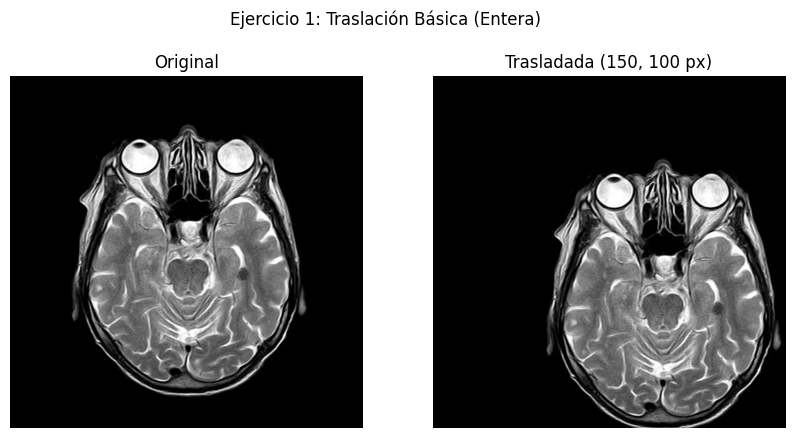

In [2]:
imagen_cabeza = cv2.imread('/content/cabeza.jpg')
# Si la imagen se lee en BGR con OpenCV, la convertimos a RGB para Matplotlib
if imagen_cabeza is not None:
  imagen_cabeza = cv2.cvtColor(imagen_cabeza, cv2.COLOR_BGR2RGB)
  h, w = imagen_cabeza.shape[:2]

  # Matriz de traslación entera: subimos a 150 y 100 píxeles para que se aprecie bien el movimiento
  M_entera = np.float32([[1, 0, 150], [0, 1, 100]])
  trasladada_entera = cv2.warpAffine(imagen_cabeza, M_entera, (w, h))
  # Esto es solo formalidad de formato :)
  plt.figure(figsize=(10, 5))
  plt.suptitle('Ejercicio 1: Traslación Básica (Entera)')
  plt.subplot(1, 2, 1)
  plt.imshow(imagen_cabeza)
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(trasladada_entera)
  plt.title('Trasladada (150, 100 px)')
  plt.axis('off')
  plt.show()

### EJERCICIO 2: Traslación con Valores Decimales

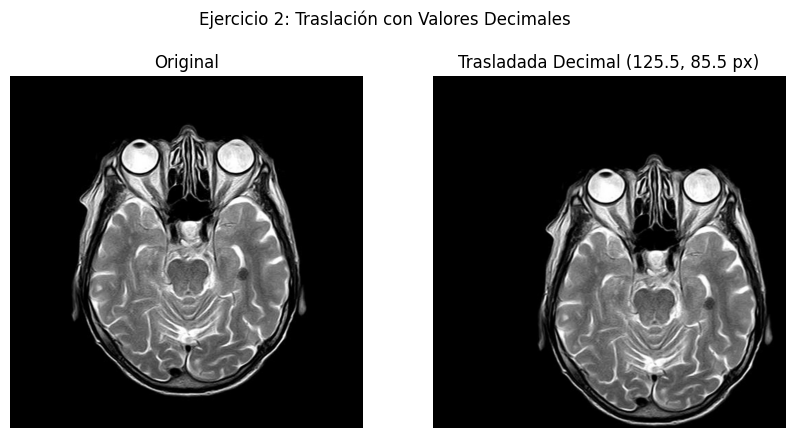

In [3]:
if imagen_cabeza is not None:
  # Matriz de traslación fraccional: aplicamos 125.5 y 85.5 para notar el desplazamiento decimal
  M_decimal = np.float32([[1, 0, 125.5], [0, 1, 85.5]])
  # Usamos la interpolación bilineal (cv2.INTER_LINEAR) para manejar los decimales
  trasladada_decimal = cv2.warpAffine(
      imagen_cabeza, M_decimal, (w, h), flags=cv2.INTER_LINEAR
  )
  # De nuevo solo formalidad de formato :)
  plt.figure(figsize=(10, 5))
  plt.suptitle('Ejercicio 2: Traslación con Valores Decimales')
  plt.subplot(1, 2, 1)
  plt.imshow(imagen_cabeza)
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(trasladada_decimal)
  plt.title('Trasladada Decimal (125.5, 85.5 px)')
  plt.axis('off')
  plt.show()

### EJERCICIO 3: Traslación + Rotación (60°)

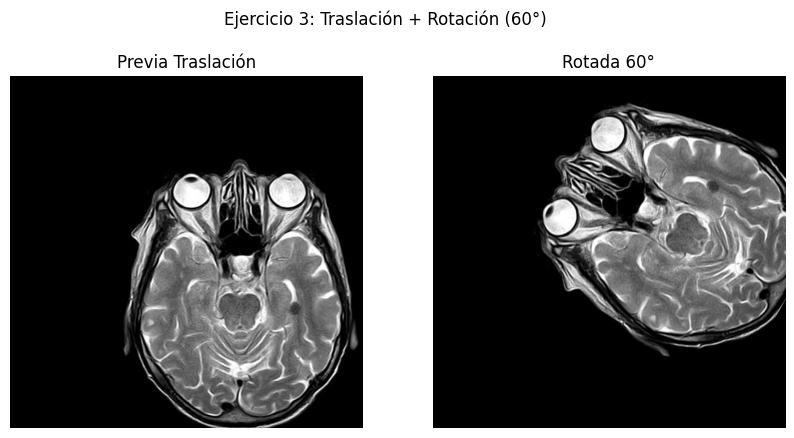

In [4]:
if imagen_cabeza is not None:
  # Definir el centro de la imagen como pivote
  centro = (w // 2, h // 2)
  # Obtener la matriz de rotación de 60 grados con escala 1.0 para que la rotación sea muy clara
  M_rotacion = cv2.getRotationMatrix2D(centro, 60, 1.0)
  rotada = cv2.warpAffine(trasladada_entera, M_rotacion, (w, h))
  # formatito
  plt.figure(figsize=(10, 5))
  plt.suptitle('Ejercicio 3: Traslación + Rotación (60°)')
  plt.subplot(1, 2, 1)
  plt.imshow(trasladada_entera)
  plt.title('Previa Traslación')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(rotada)
  plt.title('Rotada 60°')
  plt.axis('off')
  plt.show()

### EJERCICIO 4: Traslación + Rotación + Escalado

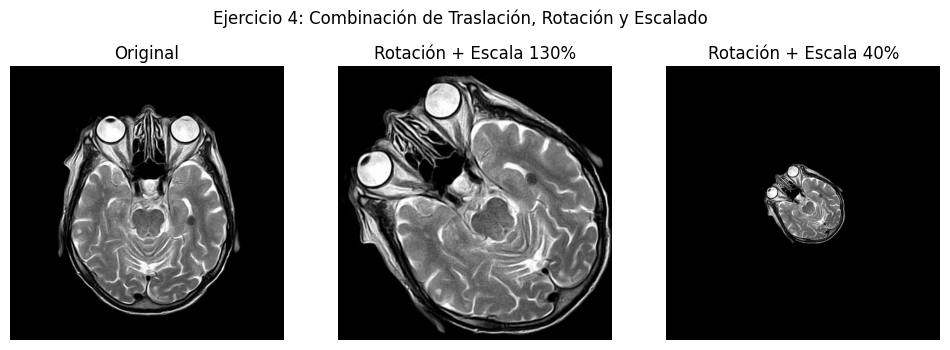

In [5]:
if imagen_cabeza is not None:
  # En el primer caso hacemos una ampliación al 130% (escala 1.3)
  M_escala_130 = cv2.getRotationMatrix2D(centro, 45, 1.3)
  ampliada = cv2.warpAffine(imagen_cabeza, M_escala_130, (w, h))

  # En el segundo caso hacemos una reducción al 40% (escala 0.4)
  M_escala_40 = cv2.getRotationMatrix2D(centro, 45, 0.4)
  reducida = cv2.warpAffine(imagen_cabeza, M_escala_40, (w, h))
  # formatito
  plt.figure(figsize=(12, 4))
  plt.suptitle('Ejercicio 4: Combinación de Traslación, Rotación y Escalado')
  plt.subplot(1, 3, 1)
  plt.imshow(imagen_cabeza)
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1, 3, 2)
  plt.imshow(ampliada)
  plt.title('Rotación + Escala 130%')
  plt.axis('off')

  plt.subplot(1, 3, 3)
  plt.imshow(reducida)
  plt.title('Rotación + Escala 40%')
  plt.axis('off')
  plt.show()

### EJERCICIO 5: Transformación Afín y Distorsión Radial

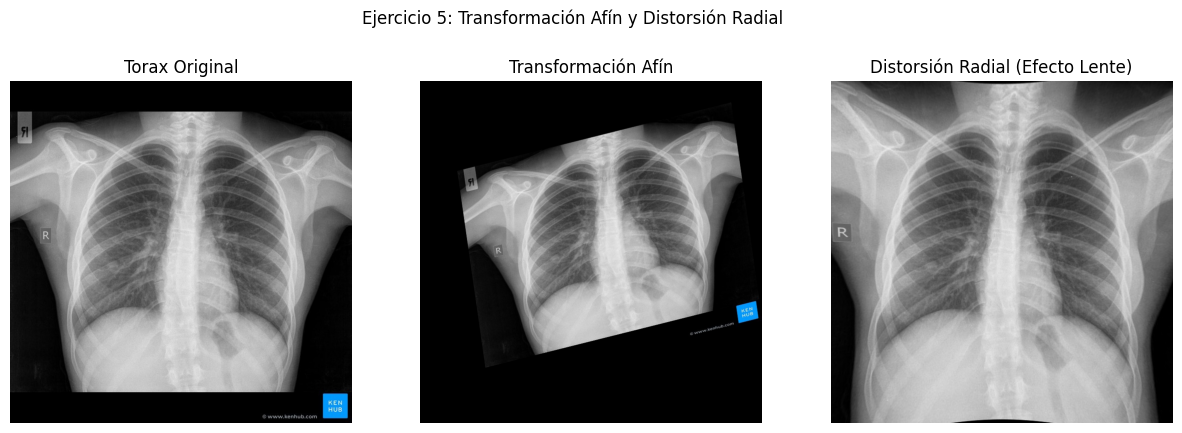

In [6]:
imagen_torax = cv2.imread('/content/torax.jpg')
if imagen_torax is not None:
  imagen_torax = cv2.cvtColor(imagen_torax, cv2.COLOR_BGR2RGB)
  ht, wt = imagen_torax.shape[:2]

  # Primero se realiza la transformación Afín usando 3 puntos de origen y 3 de destino
  puntos_origen = np.float32([[0, 0], [wt - 1, 0], [0, ht - 1]])
  puntos_destino = np.float32(
      [[wt * 0.1, ht * 0.2], [wt * 0.9, 0], [wt * 0.2, ht * 0.9]]
  )  # Acá se simula perspectiva oblicua
  matriz_afin = cv2.getAffineTransform(puntos_origen, puntos_destino)
  resultado_afin = cv2.warpAffine(imagen_torax, matriz_afin, (wt, ht))

  # Seguidamente se da la Distorsión Radial aproximada (Ojo de pez)
  # Se emplea cv2.undistort simulando parámetros de cámara o mallado de remapeo
  # Para una simulación directa de distorsión radial no lineal:
  K = np.array([[wt, 0, wt / 2], [0, ht, ht / 2], [0, 0, 1]], dtype=np.float32)
  # Coeficientes de distorsión radial más altos para notar claramente el efecto tipo lente
  dist_coeffs = np.array([-0.8, 0.5, 0, 0, 0], dtype=np.float32)
  resultado_radial = cv2.undistort(imagen_torax, K, dist_coeffs)
  # formatito
  plt.figure(figsize=(15, 5))
  plt.suptitle('Ejercicio 5: Transformación Afín y Distorsión Radial')
  plt.subplot(1, 3, 1)
  plt.imshow(imagen_torax)
  plt.title('Torax Original')
  plt.axis('off')

  plt.subplot(1, 3, 2)
  plt.imshow(resultado_afin)
  plt.title('Transformación Afín')
  plt.axis('off')

  plt.subplot(1, 3, 3)
  plt.imshow(resultado_radial)
  plt.title('Distorsión Radial (Efecto Lente)')
  plt.axis('off')
  plt.show()